README.md:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

train.jsonl: reconstructing file:   0%|          |  0.00B / 47.4MB            

train.jsonl: downloading bytes:           |  0.00B            

validation.jsonl:   0%|          | 0.00/1.19M [00:00<?, ?B/s]

test.jsonl:   0%|          | 0.00/1.18M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 200000
    })
    validation: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
    test: Dataset({
        features: ['id', 'text', 'label', 'label_text'],
        num_rows: 5000
    })
})
           id                                               text  label  \
0  en_0964290  Arrived broken. Manufacturer defect. Two of th...      0   
1  en_0690095  the cabinet dot were all detached from backing...      0   
2  en_0311558  I received my first order of this product and ...      0   
3  en_0044972  This product is a piece of shit. Do not buy. D...      0   
4  en_0784379  went through 3 in one day doesn't fit correct ...      0   

  label_text  
0          0  
1          0  
2          0  
3          0  
4          0  
(200000, 4)
Index(['id', 'text', 'label', 'label_text'], dtype='object')
Training rows: 30000
Validation rows: 3

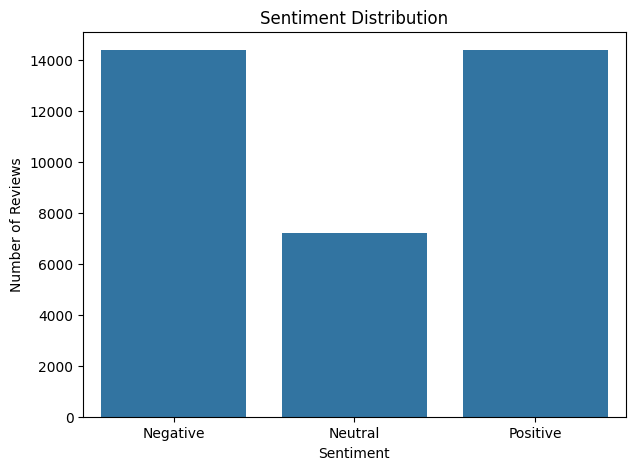

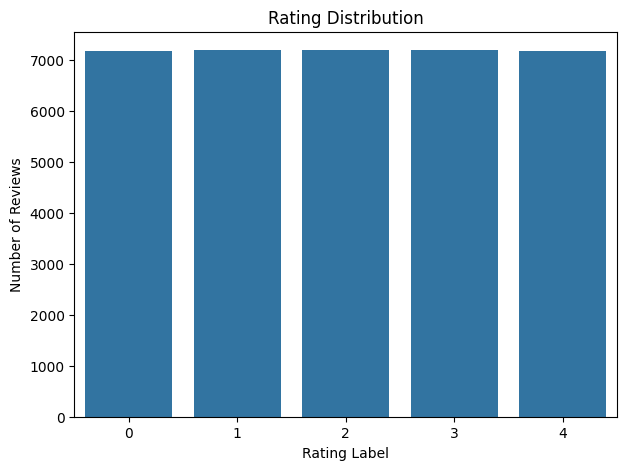

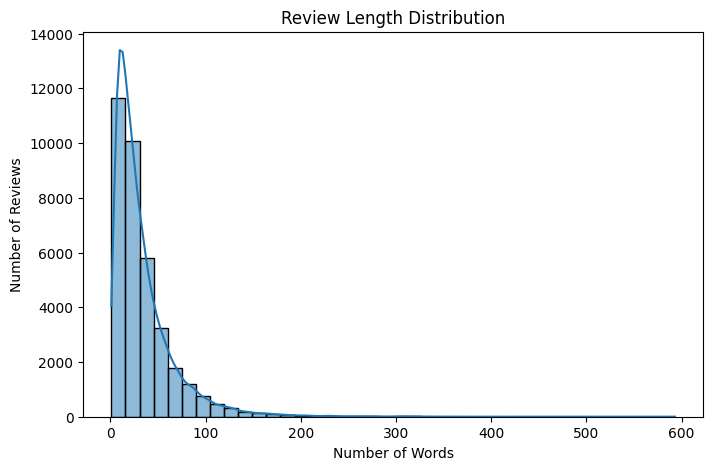

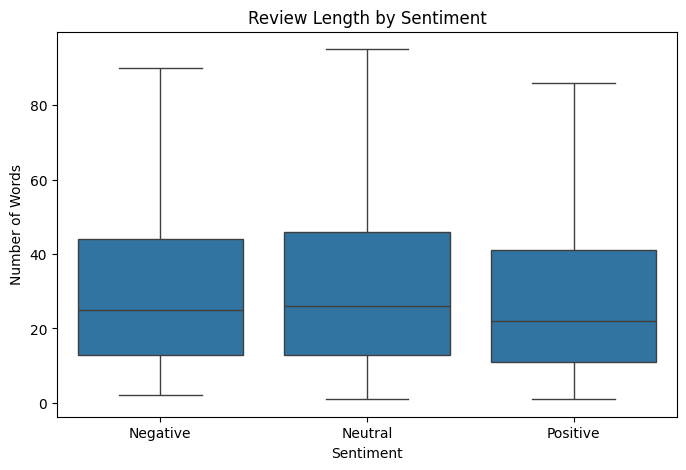


TF-IDF shapes:
Training: (29960, 10000)
Validation: (2992, 10000)
Testing: (2990, 10000)

Cleaned data sample:


,review,cleaned_review,sentiment,word_count
0,Item is a little flimsy and didn't come with i...,item is a little flimsy and didn't come with i...,Neutral,10
1,Great product! Fits well and color is true to ...,great product fits well and color is true to p...,Positive,10
2,"This is a nice quality cover, but it does not ...",this is a nice quality cover but it does not f...,Negative,49
3,I've had this small tank for a couple of years...,i've had this small tank for a couple of years...,Negative,71
4,Good product. Should have come with a screen p...,good product should have come with a screen pr...,Positive,10
5,This matches my Mediterranean bedroom set perf...,this matches my mediterranean bedroom set perf...,Positive,15
6,I bought these for added decoration during the...,i bought these for added decoration during the...,Positive,74
7,So many cool unique filters to use for phone p...,so many cool unique filters to use for phone p...,Positive,10
8,it's all I ever wanted!,it's all i ever wanted,Positive,5
9,"This relay worked twice. First time perfect, s...",this relay worked twice first time perfect sec...,Negative,28


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:
# install libraries
!pip install -q datasets

# import libraries
import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer


# load dataset
dataset = load_dataset("SetFit/amazon_reviews_multi_en")

print(dataset)


# convert dataset splits to pandas
train_data = dataset["train"].to_pandas()
validation_data = dataset["validation"].to_pandas()
test_data = dataset["test"].to_pandas()

print(train_data.head())
print(train_data.shape)
print(train_data.columns)


# use smaller samples so processing is easier
train_data, _ = train_test_split(
    train_data,
    train_size=30000,
    stratify=train_data["label"],
    random_state=42
)

validation_data, _ = train_test_split(
    validation_data,
    train_size=3000,
    stratify=validation_data["label"],
    random_state=42
)

test_data, _ = train_test_split(
    test_data,
    train_size=3000,
    stratify=test_data["label"],
    random_state=42
)

# reset indexes
train_data = train_data.reset_index(drop=True)
validation_data = validation_data.reset_index(drop=True)
test_data = test_data.reset_index(drop=True)

print("Training rows:", len(train_data))
print("Validation rows:", len(validation_data))
print("Testing rows:", len(test_data))


# rename text column
train_data = train_data.rename(columns={"text": "review"})
validation_data = validation_data.rename(columns={"text": "review"})
test_data = test_data.rename(columns={"text": "review"})


# save raw sample before cleaning
train_data.to_csv("reviews_train_raw.csv", index=False)
validation_data.to_csv("reviews_validation_raw.csv", index=False)
test_data.to_csv("reviews_test_raw.csv", index=False)


# inspect data
print("\nMissing values:")
print(train_data.isnull().sum())

print("\nDuplicate rows:")
print(train_data.duplicated().sum())

print("\nDuplicate review text:")
print(train_data["review"].duplicated().sum())

print("\nLabel distribution:")
print(train_data["label"].value_counts().sort_index())


# convert rating labels into sentiments
def get_sentiment(label):
    if label == 0 or label == 1:
        return "Negative"
    elif label == 2:
        return "Neutral"
    else:
        return "Positive"


train_data["sentiment"] = train_data["label"].apply(get_sentiment)
validation_data["sentiment"] = validation_data["label"].apply(get_sentiment)
test_data["sentiment"] = test_data["label"].apply(get_sentiment)


# simple text cleaning
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s']", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def clean_data(df):
    df = df.copy()

    # remove missing reviews and labels
    df = df.dropna(subset=["review", "label"])

    # remove duplicate reviews
    df = df.drop_duplicates(subset=["review"])

    # clean review text
    df["cleaned_review"] = df["review"].apply(clean_text)

    # remove rows that became empty
    df = df[df["cleaned_review"] != ""]

    # add review length
    df["word_count"] = df["cleaned_review"].str.split().str.len()

    return df.reset_index(drop=True)


train_clean = clean_data(train_data)
validation_clean = clean_data(validation_data)
test_clean = clean_data(test_data)

print("\nRows after cleaning:")
print("Training:", len(train_clean))
print("Validation:", len(validation_clean))
print("Testing:", len(test_clean))


# remove reviews from validation that already exist in training
training_reviews = set(train_clean["cleaned_review"])

validation_clean = validation_clean[
    ~validation_clean["cleaned_review"].isin(training_reviews)
].reset_index(drop=True)


# remove test reviews that exist in training or validation
known_reviews = set(train_clean["cleaned_review"])
known_reviews.update(validation_clean["cleaned_review"])

test_clean = test_clean[
    ~test_clean["cleaned_review"].isin(known_reviews)
].reset_index(drop=True)


# combine data for EDA
all_data = pd.concat(
    [train_clean, validation_clean, test_clean],
    ignore_index=True
)

print("\nFinal total rows:", len(all_data))
print("\nSentiment distribution:")
print(all_data["sentiment"].value_counts())


# save cleaned datasets
train_clean.to_csv("reviews_train_clean.csv", index=False)
validation_clean.to_csv("reviews_validation_clean.csv", index=False)
test_clean.to_csv("reviews_test_clean.csv", index=False)


# graph 1: sentiment distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=all_data,
    x="sentiment",
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()


# graph 2: rating distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=all_data,
    x="label"
)

plt.title("Rating Distribution")
plt.xlabel("Rating Label")
plt.ylabel("Number of Reviews")
plt.show()


# graph 3: review length
plt.figure(figsize=(8, 5))

sns.histplot(
    all_data["word_count"],
    bins=40,
    kde=True
)

plt.title("Review Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Number of Reviews")
plt.show()


# graph 4: review length by sentiment
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=all_data,
    x="sentiment",
    y="word_count",
    order=["Negative", "Neutral", "Positive"],
    showfliers=False
)

plt.title("Review Length by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Words")
plt.show()


# create TF-IDF features
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2)
)

x_train = tfidf.fit_transform(train_clean["cleaned_review"])
x_validation = tfidf.transform(validation_clean["cleaned_review"])
x_test = tfidf.transform(test_clean["cleaned_review"])

y_train = train_clean["sentiment"]
y_validation = validation_clean["sentiment"]
y_test = test_clean["sentiment"]

print("\nTF-IDF shapes:")
print("Training:", x_train.shape)
print("Validation:", x_validation.shape)
print("Testing:", x_test.shape)


# show some cleaned reviews
print("\nCleaned data sample:")
display(
    train_clean[
        ["review", "cleaned_review", "sentiment", "word_count"]
    ].head(10)
)


# download cleaned files
from google.colab import files

files.download("reviews_train_clean.csv")
files.download("reviews_validation_clean.csv")
files.download("reviews_test_clean.csv")